# Задание 3. Собственные оптимизаторы

**Основной алгоритм — AdamW.** Дополнительно реализованы Momentum, RMSProp и Adam.
Для каждого алгоритма есть тесты и эксперимент на FashionMNIST. Все реализации,
проверки, результаты и выводы находятся в этом ноутбуке.

Основа эксперимента — модель из `notebooks/pytorch_intro.ipynb`:
`Flatten → Linear(784, 512) → ReLU → Linear(512, 512) → ReLU → Linear(512, 10)`.
Из вводного ноутбука также используется последовательность
`zero_grad → loss.backward → step`.

Запуск: выполнить все ячейки сверху вниз в Python с установленными `torch`,
`torchvision`, `numpy`, `matplotlib`, `ipykernel`. При первом запуске нужен интернет
для загрузки FashionMNIST. Данные кэшируются вне репозитория во временной директории;
путь можно задать переменной окружения `FASHION_MNIST_ROOT`. Обучение по умолчанию
идёт на CPU, чтобы воспроизводить приведённый эксперимент и не зависеть от GPU.


In [1]:
import copy
import math
import os
import platform
import random
import sys
import tempfile
import time
import unittest
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from IPython.display import Markdown, display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

SEED = 42
DEVICE = torch.device("cpu")
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True})
print(f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
      f"torchvision {torchvision.__version__}; device={DEVICE}")


Python 3.12.13, PyTorch 2.14.1, torchvision 0.29.1; device=cpu


## 1. Идея алгоритмов

Пусть $g_t=\nabla_\theta L_t(\theta_{t-1})$ — градиент средней ошибки батча,
$\eta$ — learning rate, а операции с векторами выполняются покоординатно.

**Momentum.** Накапливаем направление движения:
$$b_t=\mu b_{t-1}+g_t,\qquad \theta_t=\theta_{t-1}-\eta b_t,\qquad b_0=0.$$
Согласованные градиенты усиливают движение, а смена знака частично компенсирует
накопленный импульс. Здесь нет Nesterov и dampening. Если задана L2-регуляризация,
вместо $g_t$ используется $g_t+\lambda\theta_{t-1}$.

**RMSProp.** Масштабируем шаг по скользящему среднему квадратов градиентов:
$$v_t=\alpha v_{t-1}+(1-\alpha)g_t^2,\qquad
\theta_t=\theta_{t-1}-\eta\frac{g_t}{\sqrt{v_t}+\varepsilon},\qquad v_0=0.$$
Большие градиенты уменьшают последующий эффективный шаг по соответствующей координате.
Реализован вариант без centered и momentum; $\varepsilon$ стоит **вне** корня,
как в PyTorch. L2-регуляризация при необходимости добавляется к градиенту.

**Adam.** Совмещаем сглаживание направления и адаптивный масштаб:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad
\hat v_t=\frac{v_t}{1-\beta_2^t},\qquad
\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.$$
Изначально $m_0=v_0=0$; коррекция смещения компенсирует эту нулевую инициализацию.
Счётчик $t$ ведётся отдельно для каждого параметра. В Adam с L2-регуляризацией
к градиенту добавляется $\lambda\theta_{t-1}$ **до** вычисления моментов.

**AdamW.** Моменты считаются по градиенту функции потерь, а затухание весов
применяется отдельно:
$$\theta_t=(1-\eta\lambda)\theta_{t-1}
-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.$$
Для адаптивного оптимизатора это не эквивалентно добавлению L2 к функции потерь:
L2 попадает в моменты и подвергается адаптивному масштабированию. При
$\lambda=0$ Adam и AdamW совпадают. Независимое затухание не гарантирует лучшую
точность на любом датасете: это проверяется экспериментально.

Источники формул: документация PyTorch
[SGD/Momentum](https://docs.pytorch.org/docs/2.14/generated/torch.optim.SGD.html),
[RMSProp](https://docs.pytorch.org/docs/2.14/generated/torch.optim.RMSprop.html),
[Adam](https://docs.pytorch.org/docs/2.14/generated/torch.optim.Adam.html),
[AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html);
идея независимого затухания — Loshchilov, Hutter,
[Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101).


## 2. Реализация

От `torch.optim.Optimizer` используются только управление группами параметров,
`zero_grad` и сохранение/загрузка состояния. Все обновления весов и моментов написаны
вручную на операциях с тензорами. Готовые оптимизаторы используются только в тестах.

Поддерживаются плотные вещественные параметры, группы с разными гиперпараметрами,
`closure` и восстановление состояния. `grad=None` означает пропуск параметра:
ни вес, ни его моменты, ни счётчик не меняются. Нулевой тензор градиента, напротив,
вызывает шаг, в том числе обновление импульса и weight decay.
Sparse/complex, AMSGrad, mixed precision и дифференцирование через шаг не реализованы.


In [2]:
class CustomOptimizer(torch.optim.Optimizer):
    """Общая инфраструктура; правила обновления определяют подклассы."""

    def __init__(self, params, defaults):
        super().__init__(params, defaults)
        for group in self.param_groups:
            self._validate_group(group)
            for p in group["params"]:
                if not p.is_floating_point() or p.layout != torch.strided:
                    raise TypeError("Expected dense real floating-point parameters")

    @staticmethod
    def _validate_group(group):
        for key in ("lr", "weight_decay", "eps"):
            if key in group:
                value = group[key]
                if not math.isfinite(value) or value < 0 or (key == "eps" and value == 0):
                    raise ValueError(f"Invalid {key}: {value}")
        for key in ("momentum", "alpha"):
            if key in group and not 0 <= group[key] < 1:
                raise ValueError(f"{key} must be in [0, 1)")
        if "betas" in group:
            betas = group["betas"]
            if len(betas) != 2 or not all(0 <= beta < 1 for beta in betas):
                raise ValueError("betas must contain two values in [0, 1)")

    @staticmethod
    def _gradient(p, weight_decay=0.0):
        grad = p.grad
        if grad.layout != torch.strided:
            raise RuntimeError("Sparse gradients are not supported")
        # Не меняем p.grad: регуляризованный градиент — отдельный тензор.
        return grad.add(p, alpha=weight_decay) if weight_decay else grad

    @staticmethod
    def _closure_loss(closure):
        if closure is None:
            return None
        with torch.enable_grad():
            return closure()


class Momentum(CustomOptimizer):
    def __init__(self, params, lr=1e-2, momentum=0.9, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = self._closure_loss(closure)
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = self._gradient(p, group["weight_decay"])
                state = self.state[p]
                if not state:
                    state["momentum_buffer"] = torch.zeros_like(p)
                buffer = state["momentum_buffer"]
                buffer.mul_(group["momentum"]).add_(grad)
                p.add_(buffer, alpha=-group["lr"])
        return loss


class RMSProp(CustomOptimizer):
    def __init__(self, params, lr=1e-3, alpha=0.99, eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, alpha=alpha, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = self._closure_loss(closure)
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = self._gradient(p, group["weight_decay"])
                state = self.state[p]
                if not state:
                    state["square_avg"] = torch.zeros_like(p)
                v = state["square_avg"]
                v.mul_(group["alpha"]).addcmul_(grad, grad, value=1 - group["alpha"])
                denominator = v.sqrt().add_(group["eps"])
                p.addcdiv_(grad, denominator, value=-group["lr"])
        return loss


class Adam(CustomOptimizer):
    decoupled_weight_decay = False

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = self._closure_loss(closure)
        for group in self.param_groups:
            beta1, beta2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                coupled_decay = 0.0 if self.decoupled_weight_decay else group["weight_decay"]
                grad = self._gradient(p, coupled_decay)
                state = self.state[p]
                if not state:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(p)
                    state["exp_avg_sq"] = torch.zeros_like(p)
                state["step"] += 1
                t = state["step"]
                m, v = state["exp_avg"], state["exp_avg_sq"]
                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                # sqrt(v / (1 - beta2**t)) + eps; eps находится вне корня.
                denominator = v.sqrt().div_(math.sqrt(1 - beta2 ** t)).add_(group["eps"])
                if self.decoupled_weight_decay:
                    p.mul_(1 - group["lr"] * group["weight_decay"])
                p.addcdiv_(m, denominator, value=-group["lr"] / (1 - beta1 ** t))
        return loss


class AdamW(Adam):
    # Математика моментов общая с Adam, но затухание весов применяется отдельно.
    decoupled_weight_decay = True

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        super().__init__(params, lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)


## 3. Проверки корректности

Тесты проверяют не только убывание ошибки: неверный оптимизатор тоже может её уменьшать.
Независимые ручные примеры проверяют численные шаги Momentum, RMSProp, Adam и AdamW.
Сравнение с PyTorch выполняется после каждого из 25 шагов с меняющимися градиентами,
нулевыми градиентами, пропусками и двумя группами параметров в `float64`.
Отдельно проверяются моменты, коррекция смещения, независимость состояний,
`grad=None`, `zero_grad`, `closure`, сохранение состояния и минимум квадратичной функции.


In [3]:
OPTIMIZER_CASES = [
    (Momentum, torch.optim.SGD, dict(lr=0.03, momentum=0.8, weight_decay=0.07)),
    (RMSProp, torch.optim.RMSprop, dict(lr=0.01, alpha=0.85, eps=1e-6, weight_decay=0.07)),
    (Adam, torch.optim.Adam, dict(lr=0.02, betas=(0.8, 0.95), eps=1e-6, weight_decay=0.07)),
    (AdamW, torch.optim.AdamW, dict(lr=0.02, betas=(0.8, 0.95), eps=1e-6, weight_decay=0.07)),
]


class OptimizerTests(unittest.TestCase):
    def assertTensorClose(self, actual, expected, atol=1e-12, rtol=1e-10):
        expected = torch.as_tensor(expected, dtype=actual.dtype, device=actual.device)
        torch.testing.assert_close(actual, expected, atol=atol, rtol=rtol)

    def test_manual_momentum_two_steps(self):
        p = nn.Parameter(torch.tensor([1.0, -2.0], dtype=torch.float64))
        opt = Momentum([p], lr=0.1, momentum=0.5)
        p.grad = torch.tensor([2.0, -4.0], dtype=p.dtype)
        opt.step()
        self.assertTensorClose(p, [0.8, -1.6])
        p.grad = torch.tensor([-1.0, 2.0], dtype=p.dtype)
        opt.step()  # b_2 = 0.5 * [2, -4] + [-1, 2] = [0, 0].
        self.assertTensorClose(p, [0.8, -1.6])

    def test_manual_rmsprop_two_steps(self):
        p = nn.Parameter(torch.tensor([1.0], dtype=torch.float64))
        opt = RMSProp([p], lr=0.1, alpha=0.5, eps=0.1)
        p.grad = torch.tensor([2.0], dtype=p.dtype)
        opt.step()  # v_1 = 2.
        expected = 1.0 - 0.2 / (math.sqrt(2.0) + 0.1)
        self.assertTensorClose(p, [expected])
        p.grad = torch.tensor([-1.0], dtype=p.dtype)
        opt.step()  # v_2 = 1.5.
        expected += 0.1 / (math.sqrt(1.5) + 0.1)
        self.assertTensorClose(p, [expected])

    def test_manual_adam_bias_correction_and_adamw_decay(self):
        for cls, decay in [(Adam, 0.0), (AdamW, 0.2)]:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.tensor([1.0], dtype=torch.float64))
                opt = cls([p], lr=0.1, betas=(0.5, 0.5), eps=0.1, weight_decay=decay)
                p.grad = torch.tensor([2.0], dtype=p.dtype)
                opt.step()  # m_hat_1 = 2, v_hat_1 = 4.
                expected = (1 - 0.1 * decay) - 0.1 * 2.0 / 2.1
                self.assertTensorClose(p, [expected])
                p.grad = torch.tensor([0.0], dtype=p.dtype)
                opt.step()  # m_2 = 0.5, v_2 = 1, bias factor = 0.75.
                expected = expected * (1 - 0.1 * decay) - 0.1 * (2 / 3) / (math.sqrt(4 / 3) + 0.1)
                self.assertTensorClose(p, [expected])

    def test_matches_torch_multiple_steps_groups_and_state(self):
        for cls, reference_cls, kwargs in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                generator = torch.Generator().manual_seed(17)
                params = [nn.Parameter(torch.randn(shape, generator=generator, dtype=torch.float64))
                          for shape in [(3, 2), (2,), ()]]
                refs = [nn.Parameter(p.detach().clone()) for p in params]

                def groups(items):
                    return [{"params": items[:1]},
                            {"params": items[1:], "lr": 0.004, "weight_decay": 0.0}]

                opt = cls(groups(params), **kwargs)
                ref = reference_cls(groups(refs), foreach=False, **kwargs)
                for step in range(25):
                    for i, (p, q) in enumerate(zip(params, refs)):
                        if (step + 2 * i) % 7 == 0:
                            p.grad = q.grad = None
                        else:
                            grad = torch.randn(p.shape, generator=generator, dtype=p.dtype)
                            if step % 5 == 0:
                                grad.zero_()
                            p.grad, q.grad = grad.clone(), grad.clone()
                    original_grads = [None if p.grad is None else p.grad.clone() for p in params]
                    opt.step()
                    ref.step()
                    for p, q, grad in zip(params, refs, original_grads):
                        self.assertTensorClose(p, q)
                        if grad is not None:
                            self.assertTensorClose(p.grad, grad, atol=0, rtol=0)
                        for key, value in opt.state.get(p, {}).items():
                            if isinstance(value, torch.Tensor):
                                self.assertTensorClose(value, ref.state[q][key])
                                self.assertFalse(value.requires_grad)
                            else:
                                self.assertEqual(value, int(ref.state[q][key]))
                        self.assertTrue(p.is_leaf)
                        self.assertIsNone(p.grad_fn)

    def test_none_gradient_skips_parameter_and_state(self):
        for cls, _, kwargs in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.tensor([2.0], dtype=torch.float64))
                opt = cls([p], **kwargs)
                opt.step()
                self.assertNotIn(p, opt.state)
                self.assertTensorClose(p, [2.0])
                p.grad = torch.ones_like(p)
                opt.step()
                before, state = p.detach().clone(), copy.deepcopy(opt.state[p])
                p.grad = None
                opt.step()
                self.assertTensorClose(p, before, atol=0, rtol=0)
                for key, value in state.items():
                    if isinstance(value, torch.Tensor):
                        self.assertTensorClose(opt.state[p][key], value, atol=0, rtol=0)
                    else:
                        self.assertEqual(opt.state[p][key], value)

    def test_zero_grad_both_modes(self):
        for cls, _, kwargs in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.tensor([1.0]))
                opt = cls([p], **kwargs)
                p.square().sum().backward()
                opt.zero_grad(set_to_none=False)
                self.assertTensorClose(p.grad, [0.0])
                p.square().sum().backward()
                self.assertTensorClose(p.grad, [2.0])
                opt.zero_grad(set_to_none=True)
                self.assertIsNone(p.grad)

    def test_adamw_zero_gradient_decay_is_decoupled(self):
        p = nn.Parameter(torch.tensor([2.0, -3.0], dtype=torch.float64))
        opt = AdamW([p], lr=0.1, weight_decay=0.2)
        p.grad = torch.zeros_like(p)
        opt.step()
        self.assertTensorClose(p, [1.96, -2.94])
        self.assertTensorClose(opt.state[p]["exp_avg"], [0.0, 0.0])
        self.assertTensorClose(opt.state[p]["exp_avg_sq"], [0.0, 0.0])

    def test_adam_and_adamw_agree_without_decay(self):
        p = nn.Parameter(torch.tensor([1.0, -1.0], dtype=torch.float64))
        q = nn.Parameter(p.detach().clone())
        a, b = Adam([p]), AdamW([q], weight_decay=0.0)
        for g in ([1.0, -2.0], [0.0, 0.0], [-0.5, 3.0]):
            p.grad = torch.tensor(g, dtype=p.dtype)
            q.grad = p.grad.clone()
            a.step()
            b.step()
        self.assertTensorClose(p, q, atol=0, rtol=0)

    def test_zero_learning_rate(self):
        for cls, _, kwargs in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.tensor([1.0, -2.0]))
                opt = cls([p], **dict(kwargs, lr=0.0))
                p.grad = torch.ones_like(p)
                opt.step()
                self.assertTensorClose(p, [1.0, -2.0], atol=0, rtol=0)

    def test_closure_and_quadratic_convergence(self):
        target = torch.tensor([1.5, -0.5], dtype=torch.float64)
        for cls, _, _ in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.tensor([-3.0, 2.0], dtype=torch.float64))
                kwargs = {"lr": 0.05, "weight_decay": 0.0}
                if cls is RMSProp:
                    kwargs["eps"] = 0.1  # Стабильный шаг около минимума.
                opt = cls([p], **kwargs)
                calls = []

                def closure():
                    calls.append(True)
                    opt.zero_grad()
                    loss = (p - target).square().sum()
                    loss.backward()
                    return loss

                initial_loss = (p - target).square().sum().item()
                returned = opt.step(closure)
                self.assertAlmostEqual(returned.item(), initial_loss)
                self.assertEqual(len(calls), 1)
                for _ in range(599):
                    opt.step(closure)
                self.assertLess((p - target).square().sum().item(), 1e-6)

    def test_state_dict_resume(self):
        for cls, _, kwargs in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.tensor([1.0, -2.0], dtype=torch.float64))
                opt = cls([p], **kwargs)
                for i in range(4):
                    p.grad = torch.tensor([i + 0.5, -0.2], dtype=p.dtype)
                    opt.step()
                q = nn.Parameter(p.detach().clone())
                restored = cls([q], **kwargs)
                restored.load_state_dict(copy.deepcopy(opt.state_dict()))
                for i in range(6):
                    p.grad = torch.tensor([-0.3, i + 0.1], dtype=p.dtype)
                    q.grad = p.grad.clone()
                    opt.step()
                    restored.step()
                    self.assertTensorClose(p, q, atol=0, rtol=0)

    def test_invalid_hyperparameters_and_sparse_gradients(self):
        invalid = [
            (Momentum, {"lr": -1}), (Momentum, {"momentum": 1.0}),
            (RMSProp, {"alpha": -0.1}), (RMSProp, {"eps": 0}),
            (Adam, {"betas": (0.9, 1.0)}), (AdamW, {"weight_decay": -0.1}),
            (AdamW, {"lr": float("nan")}),
        ]
        for cls, kwargs in invalid:
            with self.subTest(optimizer=cls.__name__, kwargs=kwargs):
                with self.assertRaises(ValueError):
                    cls([nn.Parameter(torch.ones(2))], **kwargs)
        for cls, _, kwargs in OPTIMIZER_CASES:
            with self.subTest(optimizer=cls.__name__):
                p = nn.Parameter(torch.ones(2))
                with self.assertRaises(ValueError):
                    cls([{"params": [p], "lr": -0.1}], **kwargs)
                opt = cls([p], **kwargs)
                p.grad = torch.sparse_coo_tensor([[0]], [1.0], size=(2,), check_invariants=True)
                with self.assertRaisesRegex(RuntimeError, "Sparse"):
                    opt.step()


suite = unittest.defaultTestLoader.loadTestsFromTestCase(OptimizerTests)
test_result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
assert test_result.wasSuccessful(), "Обучение нельзя начинать с проваленными тестами"


test_adam_and_adamw_agree_without_decay (__main__.OptimizerTests.test_adam_and_adamw_agree_without_decay) ... 

ok


test_adamw_zero_gradient_decay_is_decoupled (__main__.OptimizerTests.test_adamw_zero_gradient_decay_is_decoupled) ... 

ok


test_closure_and_quadratic_convergence (__main__.OptimizerTests.test_closure_and_quadratic_convergence) ... 

ok


... (15 outputs left out)

ok


test_zero_learning_rate (__main__.OptimizerTests.test_zero_learning_rate) ... 

ok


----------------------------------------------------------------------
Ran 12 tests in 0.145s

OK


## 4. FashionMNIST: постановка эксперимента

Используется весь исходный датасет: 60 000 обучающих и 10 000 тестовых изображений.
Из обучающей части выделяем 6 000 объектов для валидации (по 600 каждого класса),
оставшиеся 54 000 используем для обучения. Разбиение фиксировано.
Пиксели переводятся из $[0,255]$ в $[0,1]$, как при `ToTensor` на занятии;
дополнительная нормализация и аугментация не применяются.

Для каждого оптимизатора: 8 эпох, batch size 256, одна и та же начальная модель
и один и тот же порядок батчей. Гиперпараметры заданы заранее, без подбора по test.
У Momentum learning rate 0.05; у RMSProp, Adam и AdamW — 0.001.
У AdamW weight decay 0.01 для весов линейных слоёв и 0 для bias;
у остальных регуляризации нет. Поэтому это демонстрация сходимости заданных
конфигураций, а не изолированное исследование влияния weight decay и не доказательство
превосходства одного оптимизатора. Проведён один запуск с фиксированным seed.

После каждой эпохи считаются validation loss и accuracy; лучшая эпоха выбирается
по минимальной validation loss. Официальный test используется один раз для каждого
выбранного состояния модели после завершения всех обучений.


In [4]:
class FashionMNISTHTTPS(FashionMNIST):
    # Официальное HTTPS-зеркало; контрольные суммы наследуются от torchvision.
    mirrors = ["https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"]


DATA_ROOT = Path(os.environ.get(
    "FASHION_MNIST_ROOT", str(Path(tempfile.gettempdir()) / "spbu_fashion_mnist_task3")
))
raw_train = FashionMNISTHTTPS(root=DATA_ROOT, train=True, download=True)
split_generator = torch.Generator().manual_seed(SEED)
train_parts, val_parts = [], []
for label in range(10):
    indices = torch.where(raw_train.targets == label)[0]
    indices = indices[torch.randperm(len(indices), generator=split_generator)]
    val_parts.append(indices[:600])
    train_parts.append(indices[600:])
train_indices, val_indices = torch.cat(train_parts), torch.cat(val_parts)
assert len(train_indices) == 54000 and len(val_indices) == 6000
assert torch.unique(torch.cat([train_indices, val_indices])).numel() == 60000

# uint8 сохраняет компактное представление; преобразование выполняется на батче.
train_dataset = TensorDataset(raw_train.data[train_indices].unsqueeze(1), raw_train.targets[train_indices])
val_dataset = TensorDataset(raw_train.data[val_indices].unsqueeze(1), raw_train.targets[val_indices])
BATCH_SIZE = 256
EPOCHS = 8


def make_train_loader():
    # Новый генератор в каждом запуске обеспечивает одинаковые перестановки эпох.
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED + 1), num_workers=0)


train_eval_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)
print(f"Train: {len(train_dataset)}, validation: {len(val_dataset)}, test: 10000")
print("Число объектов каждого класса в validation:", torch.bincount(raw_train.targets[val_indices]).tolist())


Train: 54000, validation: 6000, test: 10000
Число объектов каждого класса в validation: [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]


In [5]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(
            nn.Linear(28 * 28, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.fc(self.flatten(x))


seed_everything()
initial_model = NeuralNetwork()
initial_state = copy.deepcopy(initial_model.state_dict())
criterion = nn.CrossEntropyLoss()


def prepare_batch(x, y):
    return x.to(DEVICE, dtype=torch.float32).div(255.0), y.to(DEVICE)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = prepare_batch(x, y)
        logits = model(x)
        loss_sum += criterion(logits, y).item() * y.numel()
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.numel()
    return loss_sum / count, correct / count


def gradient_norm(model):
    # L2-норма объединённого вектора градиентов ВСЕХ параметров, включая bias.
    return torch.stack([p.grad.detach().square().sum()
                        for p in model.parameters() if p.grad is not None]).sum().sqrt().item()


@torch.no_grad()
def weight_snapshot(model):
    # Только матрицы весов, отдельно для каждого линейного слоя; bias исключены.
    return {name: p.detach().cpu().flatten().clone()
            for name, p in model.named_parameters() if name.endswith("weight")}


def train_epoch(model, optimizer, loader):
    model.train()
    loss_sum, correct, count, grad_norms = 0.0, 0, 0, []
    for x, y in loader:
        x, y = prepare_batch(x, y)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        norm = gradient_norm(model)  # До step, без clipping и weight decay.
        if not math.isfinite(loss.item()) or not math.isfinite(norm):
            raise FloatingPointError("Non-finite training loss or gradient")
        grad_norms.append(norm)
        optimizer.step()
        loss_sum += loss.item() * y.numel()
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.numel()
    return dict(train_loss=loss_sum / count, train_accuracy=correct / count,
                grad_mean=float(np.mean(grad_norms)), grad_max=float(np.max(grad_norms)))


CONFIGS = {
    "Momentum": (Momentum, dict(lr=0.05, momentum=0.9, weight_decay=0.0)),
    "RMSProp": (RMSProp, dict(lr=0.001, alpha=0.99, eps=1e-8, weight_decay=0.0)),
    "Adam": (Adam, dict(lr=0.001, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0)),
    "AdamW": (AdamW, dict(lr=0.001, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01)),
}


def make_optimizer(name, model):
    cls, kwargs = CONFIGS[name]
    if name == "AdamW":
        groups = [
            {"params": [p for n, p in model.named_parameters() if n.endswith("weight")]},
            {"params": [p for n, p in model.named_parameters() if n.endswith("bias")],
             "weight_decay": 0.0},
        ]
        return cls(groups, **kwargs)
    return cls(model.parameters(), **kwargs)


print(initial_model)
print("Число обучаемых параметров:", sum(p.numel() for p in initial_model.parameters()))
for name, (_, kwargs) in CONFIGS.items():
    print(name, kwargs)


NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)
Число обучаемых параметров: 669706
Momentum {'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.0}
RMSProp {'lr': 0.001, 'alpha': 0.99, 'eps': 1e-08, 'weight_decay': 0.0}
Adam {'lr': 0.001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0.0}
AdamW {'lr': 0.001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0.01}


## 5. Обучение и наблюдаемые величины

`train_loss` — средняя по объектам ошибка батчей **во время** обучения: веса меняются
между батчами. `val_loss` — ошибка фиксированной модели в конце эпохи. Эти две
величины имеют разный способ измерения. Эпоха 0 — общая начальная модель до обучения.

Норма градиента батча:
$$\|\nabla L_B\|_2 = \sqrt{\sum_{p}\sum_j (\partial L_B/\partial p_j)^2}.$$
Для каждой эпохи выводятся среднее и максимум этих норм по батчам. Это норма
градиента cross-entropy, а не норма обновления весов или градиента с регуляризацией.
Норма не обязана монотонно уменьшаться при успешном обучении.

Для анализа весов сохраняются распределения каждого линейного слоя в эпохах 0, 4 и 8.

Графики сходимости показывают эпохи 1–8: начальные значения эпохи 0
напечатаны отдельно, чтобы их большой масштаб не скрывал различия после обучения.


In [6]:
initial_model = initial_model.to(DEVICE)
initial_train_loss, initial_train_accuracy = evaluate(initial_model, train_eval_loader)
initial_val_loss, initial_val_accuracy = evaluate(initial_model, val_loader)
initial_weights = weight_snapshot(initial_model)
print(f"До обучения: train CE={initial_train_loss:.4f}, "
      f"val CE={initial_val_loss:.4f}, val accuracy={initial_val_accuracy:.2%}")

results = {}
for name in CONFIGS:
    seed_everything()
    model = NeuralNetwork().to(DEVICE)
    model.load_state_dict(initial_state)
    optimizer = make_optimizer(name, model)
    train_loader = make_train_loader()
    history = [dict(epoch=0, train_loss=initial_train_loss, train_accuracy=initial_train_accuracy,
                    val_loss=initial_val_loss, val_accuracy=initial_val_accuracy,
                    grad_mean=float("nan"), grad_max=float("nan"))]
    snapshots = {0: initial_weights}
    best_val_loss, best_epoch, best_state = initial_val_loss, 0, copy.deepcopy(initial_state)
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        metrics = train_epoch(model, optimizer, train_loader)
        val_loss, val_accuracy = evaluate(model, val_loader)
        metrics.update(epoch=epoch, val_loss=val_loss, val_accuracy=val_accuracy)
        history.append(metrics)
        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if epoch in {EPOCHS // 2, EPOCHS}:
            snapshots[epoch] = weight_snapshot(model)
        print(f"{name:8s} | {epoch:2d}/{EPOCHS} | train CE {metrics['train_loss']:.4f} | "
              f"val CE {val_loss:.4f} | val acc {val_accuracy:.2%} | "
              f"grad mean/max {metrics['grad_mean']:.3f}/{metrics['grad_max']:.3f}", flush=True)
    elapsed = time.perf_counter() - started
    results[name] = dict(history=history, snapshots=snapshots, best_epoch=best_epoch,
                         best_val_loss=best_val_loss, best_state=best_state, seconds=elapsed)
    assert history[-1]["train_loss"] < initial_train_loss
    assert best_val_loss < initial_val_loss
    assert all(torch.isfinite(value).all() for value in snapshots[EPOCHS].values())
    print(f"{name}: лучшая эпоха {best_epoch}, время {elapsed:.1f} с\n", flush=True)


До обучения: train CE=2.3006, val CE=2.3004, val accuracy=16.98%


Momentum |  1/8 | train CE 0.7255 | val CE 0.4676 | val acc 83.37% | grad mean/max 1.079/3.608


Momentum |  2/8 | train CE 0.4182 | val CE 0.4521 | val acc 83.32% | grad mean/max 0.910/1.598


Momentum |  3/8 | train CE 0.3700 | val CE 0.3939 | val acc 85.68% | grad mean/max 0.862/1.595


Momentum |  4/8 | train CE 0.3380 | val CE 0.3892 | val acc 85.97% | grad mean/max 0.791/1.601


Momentum |  5/8 | train CE 0.3250 | val CE 0.3536 | val acc 87.13% | grad mean/max 0.827/1.658


... (27 outputs left out)

AdamW    |  6/8 | train CE 0.2748 | val CE 0.3385 | val acc 88.40% | grad mean/max 0.773/1.444


AdamW    |  7/8 | train CE 0.2587 | val CE 0.3278 | val acc 87.97% | grad mean/max 0.756/1.552


AdamW    |  8/8 | train CE 0.2507 | val CE 0.3283 | val acc 88.30% | grad mean/max 0.771/1.627


AdamW: лучшая эпоха 7, время 4.9 с



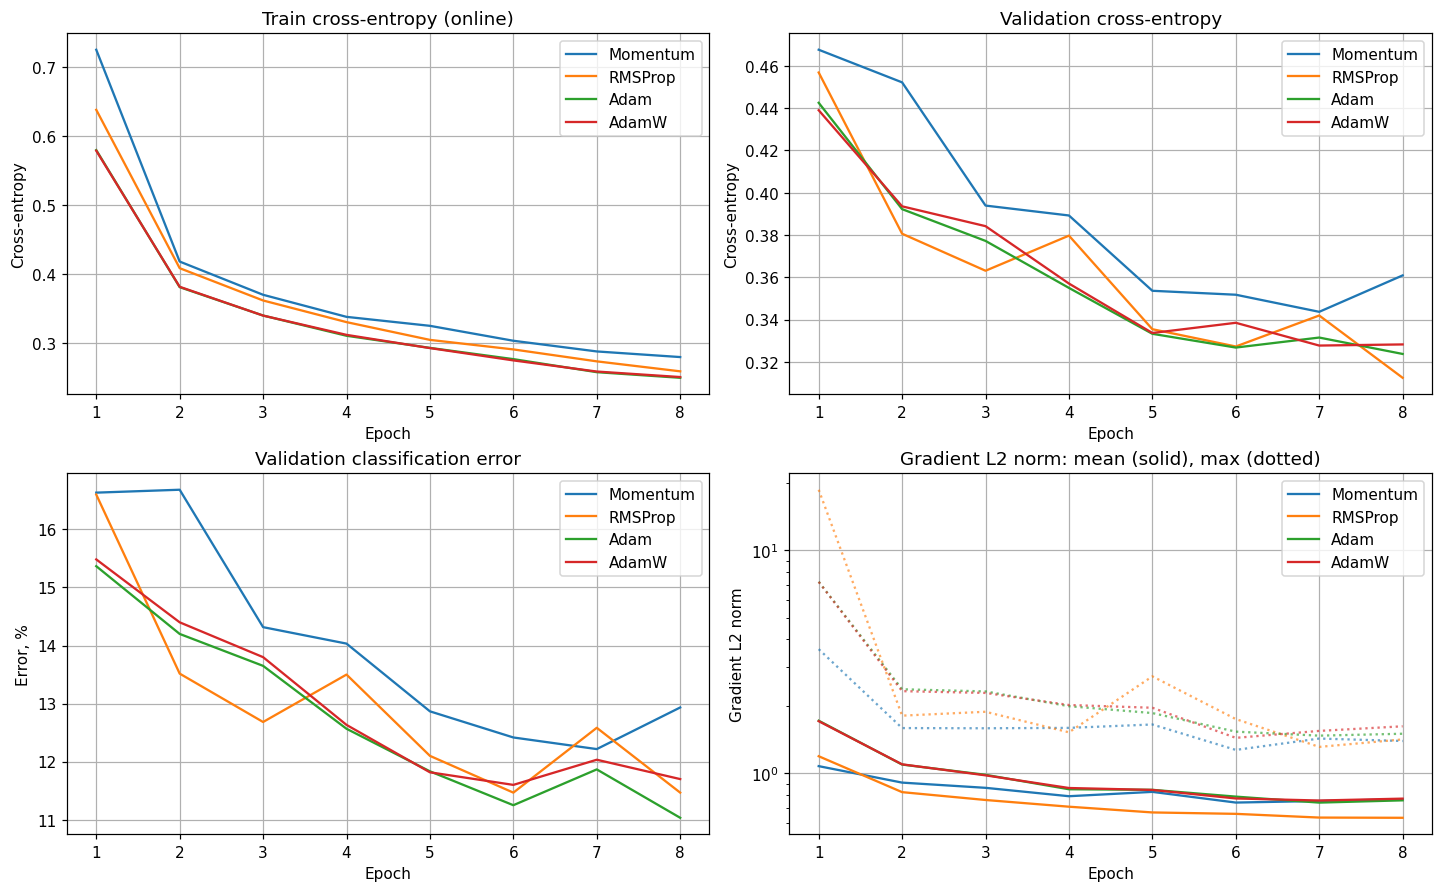

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for name, result in results.items():
    h = result["history"][1:]
    epochs = [r["epoch"] for r in h]
    line, = axes[0, 0].plot(epochs, [r["train_loss"] for r in h], label=name)
    axes[0, 1].plot(epochs, [r["val_loss"] for r in h], color=line.get_color(), label=name)
    axes[1, 0].plot(epochs, [100 * (1 - r["val_accuracy"]) for r in h],
                    color=line.get_color(), label=name)
    axes[1, 1].plot(epochs, [r["grad_mean"] for r in h],
                    color=line.get_color(), label=name)
    axes[1, 1].plot(epochs, [r["grad_max"] for r in h],
                    color=line.get_color(), linestyle=":", alpha=0.65)
titles = ["Train cross-entropy (online)", "Validation cross-entropy",
          "Validation classification error", "Gradient L2 norm: mean (solid), max (dotted)"]
ylabels = ["Cross-entropy", "Cross-entropy", "Error, %", "Gradient L2 norm"]
for ax, title, ylabel in zip(axes.flat, titles, ylabels):
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.legend()
    ax.set_xticks(range(1, EPOCHS + 1))
axes[1, 1].set_yscale("log")
plt.show()


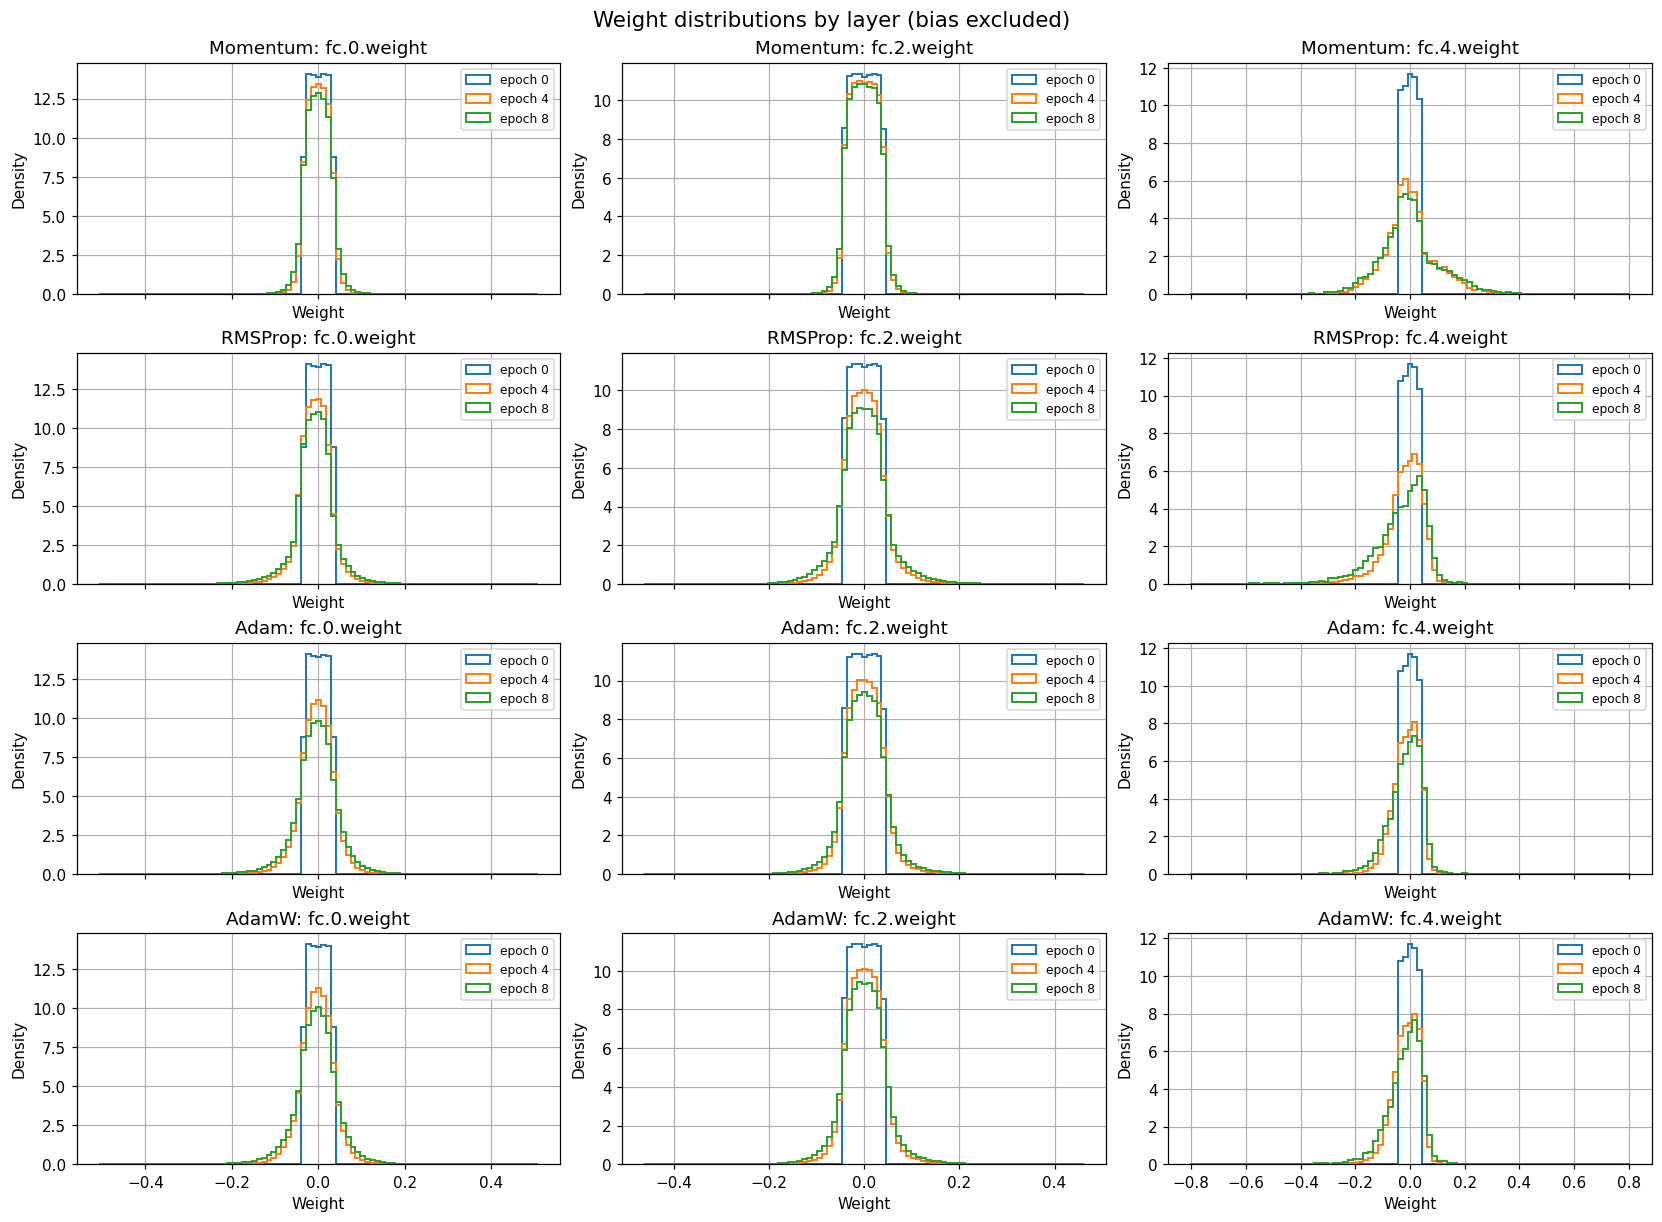

| Optimizer | Layer | Initial std | Final mean | Final std | Max abs |
|---|---|---:|---:|---:|---:|
| Momentum | fc.0.weight | 0.02062 | -0.00083 | 0.02785 | 0.24403 |
| Momentum | fc.2.weight | 0.02550 | 0.00003 | 0.02950 | 0.17705 |
| Momentum | fc.4.weight | 0.02545 | -0.00028 | 0.10537 | 0.59888 |
| RMSProp | fc.0.weight | 0.02062 | -0.00881 | 0.04518 | 0.47154 |
| RMSProp | fc.2.weight | 0.02550 | -0.00014 | 0.04926 | 0.39803 |
| RMSProp | fc.4.weight | 0.02545 | -0.03548 | 0.10132 | 0.80398 |
| Adam | fc.0.weight | 0.02062 | -0.00467 | 0.04799 | 0.50820 |
| Adam | fc.2.weight | 0.02550 | 0.00148 | 0.04483 | 0.42809 |
| Adam | fc.4.weight | 0.02545 | -0.01645 | 0.06120 | 0.37831 |
| AdamW | fc.0.weight | 0.02062 | -0.00466 | 0.04752 | 0.46087 |
| AdamW | fc.2.weight | 0.02550 | 0.00137 | 0.04510 | 0.46205 |
| AdamW | fc.4.weight | 0.02545 | -0.01722 | 0.06324 | 0.47514 |

In [8]:
layer_names = list(initial_weights)
fig, axes = plt.subplots(len(results), len(layer_names), figsize=(15, 11),
                         sharex="col", constrained_layout=True)
for column, layer in enumerate(layer_names):
    # Одни границы и интервалы для всех оптимизаторов и всех эпох данного слоя.
    arrays = [snapshot[layer].numpy() for result in results.values()
              for snapshot in result["snapshots"].values()]
    bound = max(float(np.abs(values).max()) for values in arrays)
    bins = np.linspace(-bound, bound, 90)
    for row, (name, result) in enumerate(results.items()):
        ax = axes[row, column]
        for epoch, snapshot in result["snapshots"].items():
            ax.hist(snapshot[layer].numpy(), bins=bins, density=True, histtype="step",
                    linewidth=1.3, label=f"epoch {epoch}")
        ax.set(title=f"{name}: {layer}", xlabel="Weight", ylabel="Density")
        ax.legend(fontsize=8)
fig.suptitle("Weight distributions by layer (bias excluded)", fontsize=14)
plt.show()

rows = ["| Optimizer | Layer | Initial std | Final mean | Final std | Max abs |",
        "|---|---|---:|---:|---:|---:|"]
for name, result in results.items():
    for layer, weights in result["snapshots"][EPOCHS].items():
        rows.append(f"| {name} | {layer} | {initial_weights[layer].std(unbiased=False):.5f} | "
                    f"{weights.mean():.5f} | {weights.std(unbiased=False):.5f} | "
                    f"{weights.abs().max():.5f} |")
display(Markdown("\n".join(rows)))


## 6. Итоговая оценка

Ниже каждая модель восстанавливается с эпохи, выбранной по validation loss.
Графики распределений выше относятся к последней эпохе, а не обязательно к выбранной.
Test не участвовал в выборе эпохи или гиперпараметров. Время включает обучение,
валидацию и сбор диагностик; оно зависит от оборудования и фоновой нагрузки.


In [9]:
raw_test = FashionMNISTHTTPS(root=DATA_ROOT, train=False, download=True)
test_dataset = TensorDataset(raw_test.data.unsqueeze(1), raw_test.targets)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)
rows = ["| Optimizer | Best epoch | Val CE | Val accuracy | Test CE | Test accuracy | Time, s |",
        "|---|---:|---:|---:|---:|---:|---:|"]
for name, result in results.items():
    selected_model = NeuralNetwork().to(DEVICE)
    selected_model.load_state_dict(result["best_state"])
    test_loss, test_accuracy = evaluate(selected_model, test_loader)
    result.update(test_loss=test_loss, test_accuracy=test_accuracy)
    best = result["history"][result["best_epoch"]]
    rows.append(f"| {name} | {result['best_epoch']} | {best['val_loss']:.4f} | "
                f"{best['val_accuracy']:.2%} | {test_loss:.4f} | {test_accuracy:.2%} | "
                f"{result['seconds']:.1f} |")
display(Markdown("\n".join(rows)))


| Optimizer | Best epoch | Val CE | Val accuracy | Test CE | Test accuracy | Time, s |
|---|---:|---:|---:|---:|---:|---:|
| Momentum | 7 | 0.3437 | 87.78% | 0.3472 | 87.45% | 3.8 |
| RMSProp | 8 | 0.3125 | 88.53% | 0.3295 | 88.38% | 4.2 |
| Adam | 8 | 0.3238 | 88.97% | 0.3426 | 88.32% | 4.7 |
| AdamW | 7 | 0.3278 | 87.97% | 0.3387 | 87.83% | 4.9 |

In [10]:
# Вывод опирается на реально полученные значения и обновляется при перезапуске.
best_name = min(results, key=lambda name: results[name]["best_val_loss"])
lines = ["### Выводы по выполненному запуску", "",
         f"Все четыре реализации прошли {test_result.testsRun} тестовых методов. "
         "Для всех уменьшились train и validation cross-entropy относительно инициализации.", ""]
for name, result in results.items():
    last = result["history"][-1]
    first = result["history"][1]
    lines.append(
        f"- **{name}:** train CE {initial_train_loss:.4f} → {last['train_loss']:.4f}; "
        f"лучшая val CE {result['best_val_loss']:.4f} (эпоха {result['best_epoch']}); "
        f"test accuracy {result['test_accuracy']:.2%}. "
        f"Средняя норма градиента в эпохах 1 и {EPOCHS}: "
        f"{first['grad_mean']:.3f} и {last['grad_mean']:.3f}."
    )
lines += ["", f"Минимальная validation loss в этом запуске — у **{best_name}**. "
          "Это результат одного seed и фиксированных настроек, а не общий рейтинг алгоритмов.", "",
          "Распределения весов изменились относительно инициализации; точные средние, "
          "стандартные отклонения и максимальные модули приведены выше отдельно для каждого слоя. "
          "Все сохранённые веса и измеренные нормы градиента конечны. "
          "Убывание loss не требует монотонного убывания нормы градиента.", "",
          "AdamW отделяет затухание весов от моментов, что подтверждено отдельным тестом. "
          "Для оценки именно эффекта weight decay нужны повторные запуски AdamW с разными "
          "коэффициентами и несколькими seed; здесь такого причинного вывода не делаем."]
lines += ["", "**Динамика весов.** Стандартное отклонение выходного слоя выросло "
          f"с {initial_weights['fc.4.weight'].std(unbiased=False):.4f} до "
          + ", ".join(f"{name}: {r['snapshots'][EPOCHS]['fc.4.weight'].std(unbiased=False):.4f}"
                      for name, r in results.items()) + ". "
          "Более широкий разброс весов сам по себе не определяет качество классификации.", "",
          f"**Динамика градиентов.** У RMSProp максимальная норма в первой эпохе "
          f"составила {results['RMSProp']['history'][1]['grad_max']:.2f}, "
          f"а в последней — {results['RMSProp']['history'][-1]['grad_max']:.2f}. "
          "Начальные всплески не перешли в расходимость: validation loss снизилась."]
display(Markdown("\n".join(lines)))


### Выводы по выполненному запуску

Все четыре реализации прошли 12 тестовых методов. Для всех уменьшились train и validation cross-entropy относительно инициализации.

- **Momentum:** train CE 2.3006 → 0.2797; лучшая val CE 0.3437 (эпоха 7); test accuracy 87.45%. Средняя норма градиента в эпохах 1 и 8: 1.079 и 0.766.
- **RMSProp:** train CE 2.3006 → 0.2590; лучшая val CE 0.3125 (эпоха 8); test accuracy 88.38%. Средняя норма градиента в эпохах 1 и 8: 1.195 и 0.633.
- **Adam:** train CE 2.3006 → 0.2496; лучшая val CE 0.3238 (эпоха 8); test accuracy 88.32%. Средняя норма градиента в эпохах 1 и 8: 1.724 и 0.758.
- **AdamW:** train CE 2.3006 → 0.2507; лучшая val CE 0.3278 (эпоха 7); test accuracy 87.83%. Средняя норма градиента в эпохах 1 и 8: 1.716 и 0.771.

Минимальная validation loss в этом запуске — у **RMSProp**. Это результат одного seed и фиксированных настроек, а не общий рейтинг алгоритмов.

Распределения весов изменились относительно инициализации; точные средние, стандартные отклонения и максимальные модули приведены выше отдельно для каждого слоя. Все сохранённые веса и измеренные нормы градиента конечны. Убывание loss не требует монотонного убывания нормы градиента.

AdamW отделяет затухание весов от моментов, что подтверждено отдельным тестом. Для оценки именно эффекта weight decay нужны повторные запуски AdamW с разными коэффициентами и несколькими seed; здесь такого причинного вывода не делаем.

**Динамика весов.** Стандартное отклонение выходного слоя выросло с 0.0254 до Momentum: 0.1054, RMSProp: 0.1013, Adam: 0.0612, AdamW: 0.0632. Более широкий разброс весов сам по себе не определяет качество классификации.

**Динамика градиентов.** У RMSProp максимальная норма в первой эпохе составила 18.70, а в последней — 1.42. Начальные всплески не перешли в расходимость: validation loss снизилась.